# Project 1: Predicting Used Toyota Corolla Resale Prices

**Name:** Pedro Sanchez & Anton van der Laar

The goal is to help the dealership estimate the resale value of a used Toyota Corolla and identify the car specifications that matter most when making a trade-in offer. The notebook follows the workflow used in class and answers each required question directly after the code that supports it.

In [1]:
### Step 0: Setup ----

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt
from pathlib import Path


def vif_table(model):
    X = model.model.exog
    names = model.model.exog_names
    vifs = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
    out = pd.DataFrame({'variable': names, 'VIF': vifs})
    return out[out['variable'] != 'const'].round(2).reset_index(drop=True)


def diagnostic_plots(model, y_true):
    resid, fitted = model.resid, model.fittedvalues

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    axes[0].scatter(fitted, resid, alpha=0.6)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Fitted values')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title('Residuals vs. Fitted')

    axes[1].scatter(fitted, y_true, alpha=0.6)
    lims = [min(fitted.min(), y_true.min()), max(fitted.max(), y_true.max())]
    axes[1].plot(lims, lims, color='red', linestyle='--')
    axes[1].set_xlabel('Fitted values')
    axes[1].set_ylabel('Actual values')
    axes[1].set_title('Actual vs. Fitted')

    sm.qqplot(resid, line='s', ax=axes[2])
    axes[2].set_title('Normal Q-Q')

    axes[3].hist(resid, bins=20, edgecolor='white')
    axes[3].axvline(0, color='red', linestyle='--')
    axes[3].set_xlabel('Residual')
    axes[3].set_title('Histogram of Residuals')

    plt.tight_layout()
    plt.show()


def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def scorecard(model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(sm.add_constant(X_tr, has_constant='add'))
    pred_te = model.predict(sm.add_constant(X_te, has_constant='add'))
    p = X_tr.shape[1]

    rows = {}
    for label, y, pred in [('Training set', y_tr, pred_tr), ('Test set', y_te, pred_te)]:
        r2 = r2_score(y, pred)
        rows[label] = [
            r2,
            adj_r2(r2, len(y), p),
            np.sqrt(mean_squared_error(y, pred)),
            mean_absolute_error(y, pred)
        ]

    return pd.DataFrame(
        rows,
        index=['R-squared', 'Adj. R-squared', 'RMSE', 'MAE']
    ).round(3)

In [2]:
### Step 1: Pre-processing 

# Use ToyotaCorolla.csv if it is beside the notebook. In Colab, the cell
# will ask for the file only if it cannot find it.
csv_path = Path('ToyotaCorolla.csv')

if not csv_path.exists():
    matches = sorted(Path('.').glob('ToyotaCorolla*.csv'))
    if matches:
        csv_path = matches[0]
    else:
        try:
            from google.colab import files
            print('Upload ToyotaCorolla.csv')
            files.upload()
            matches = sorted(Path('.').glob('ToyotaCorolla*.csv'))
            if matches:
                csv_path = matches[0]
        except ImportError:
            pass

if not csv_path.exists():
    raise FileNotFoundError('ToyotaCorolla.csv must be in the same folder as this notebook.')

cars_raw = pd.read_csv(csv_path)
print(f'Loaded {csv_path.name}: {cars_raw.shape[0]} rows and {cars_raw.shape[1]} columns')
print('Missing values:', int(cars_raw.isna().sum().sum()))
print(); print('Fuel types:')
print(cars_raw['Fuel_Type'].value_counts())

# Fuel_Type is categorical, so use dummy variables. CNG is the reference group.
cars = pd.get_dummies(cars_raw, columns=['Fuel_Type'], drop_first=True, dtype=int)
print(); print('Data ready for modeling.')

Loaded ToyotaCorolla.csv: 1436 rows and 39 columns
Missing values: 0

Fuel types:
Fuel_Type
Petrol    1264
Diesel     155
CNG         17
Name: count, dtype: int64

Data ready for modeling.


In [3]:
### Step 2: Split data into train and test sets 

train_data, test_data = train_test_split(
    cars,
    test_size=0.40,
    random_state=42
)

predictors = [
    'Age_08_04', 'KM', 'CC', 'HP', 'Automatic', 'Doors', 'Quarterly_Tax',
    'Mfr_Guarantee', 'Guarantee_Period', 'Airco', 'Automatic_airco',
    'CD_Player', 'Powered_Windows', 'Sport_Model', 'Tow_Bar',
    'Fuel_Type_Diesel', 'Fuel_Type_Petrol'
]

X_train = train_data[predictors].astype(float)
y_train = train_data['Price']
X_test = test_data[predictors].astype(float)
y_test = test_data['Price']

print(f'Training cars: {len(train_data)} ({len(train_data)/len(cars):.1%})')
print(f'Test cars:     {len(test_data)} ({len(test_data)/len(cars):.1%})')
print(f'Mean price - training: {y_train.mean():,.0f} EUR')
print(f'Mean price - test:     {y_test.mean():,.0f} EUR')

Training cars: 861 (60.0%)
Test cars:     575 (40.0%)
Mean price - training: 10,760 EUR
Mean price - test:     10,688 EUR


### Q1. Split the data into training (60%) and test (40%) datasets

The random split gives **861 training cars and 575 test cars**, which is almost exactly 60/40. The mean price is also very similar in the two groups (about EUR 10.8k vs. EUR 10.7k), so the split looks balanced. `Fuel_Type` is one requested predictor, but after dummy coding it is represented by Diesel and Petrol indicators, with CNG as the reference group.

In [2]:
### Step 5: Initial multiple regression 

model_base = sm.OLS(
    y_train,
    sm.add_constant(X_train, has_constant='add')
).fit()

print(model_base.summary())

NameError: name 'sm' is not defined

### Q2. Multiple linear regression with the specified predictors

The initial model has **R-squared = 0.893** and **adjusted R-squared = 0.891** on the training data. Age and mileage both have negative coefficients, while horsepower, road tax, automatic climate control and several convenience features have positive coefficients. For example, holding the other variables fixed, one extra month of age is associated with about **EUR 112 less**, another 10,000 km with about **EUR 175 less**, and automatic climate control with about **EUR 3,043 more** in this first model.

The overall F-test is highly significant, so the predictors are useful as a group. I do not treat every individual coefficient as a clean standalone effect because some engine and fuel variables overlap with each other.

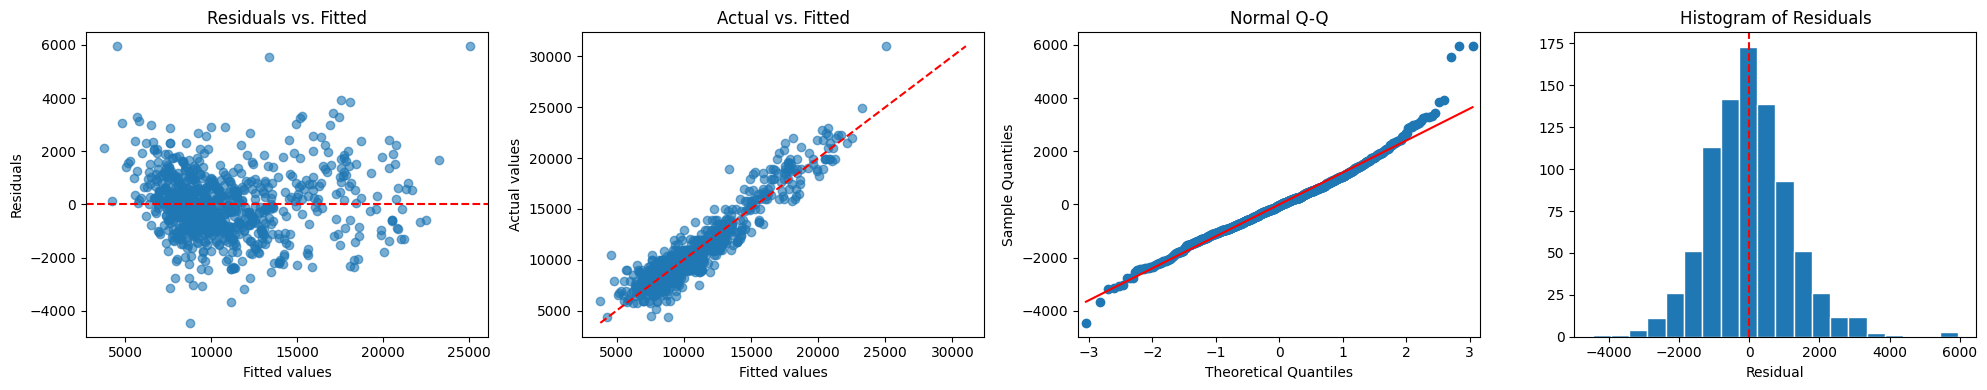

In [5]:
# Residual diagnostics from class.
diagnostic_plots(model_base, y_train)

### Q3. Check for evidence of obvious model misspecification by plotting residuals

The residual plots show two things worth following up. First, the residual spread gets wider as fitted price rises, so the variance is not perfectly constant. Second, there are a few very large residuals and the Q-Q plot moves away from the line in the tails. There is also a small amount of curvature in residuals vs. fitted.

The model is not unusable, and actual and fitted prices still line up reasonably well. But the plots say I should inspect unusual records and later test a non-linear age relationship.

In [6]:
# Rank variables by t-statistic and standardized coefficient.
importance = pd.DataFrame({
    'coef_EUR': model_base.params.drop('const'),
    't_stat': model_base.tvalues.drop('const'),
    'p_value': model_base.pvalues.drop('const'),
    'std_coef': model_base.params.drop('const') * X_train.std() / y_train.std()
})
importance = importance.reindex(
    importance['t_stat'].abs().sort_values(ascending=False).index
)

print('Most important variables in the initial model:')
print(importance.head(10).round(3))

print(); print('VIF check:')
print(vif_table(model_base))

Most important variables in the initial model:
                  coef_EUR  t_stat  p_value  std_coef
Age_08_04         -111.625 -31.922      0.0    -0.579
Automatic_airco   3043.117  14.351      0.0     0.190
KM                  -0.018 -11.223      0.0    -0.183
Quarterly_Tax       16.979   8.141      0.0     0.197
HP                  30.429   8.011      0.0     0.125
Guarantee_Period    73.651   4.756      0.0     0.058
Fuel_Type_Petrol  2000.910   4.447      0.0     0.185
Fuel_Type_Diesel  1844.191   4.316      0.0     0.164
Powered_Windows    384.157   3.783      0.0     0.052
Doors              167.825   3.706      0.0     0.044

VIF check:
            variable    VIF
0          Age_08_04   2.59
1                 KM   2.10
2                 CC   1.18
3                 HP   1.91
4          Automatic   1.04
5              Doors   1.09
6      Quarterly_Tax   4.60
7      Mfr_Guarantee   1.12
8   Guarantee_Period   1.18
9              Airco   1.65
10   Automatic_airco   1.38
11         

### Q4. What appear to be the three or four most important car specifications?

The clearest drivers in the initial model are:

1. **Age**, by a large margin. It has the biggest t-statistic and the largest standardized effect.
2. **Automatic climate control**, the strongest single option.
3. **Mileage**, which is strongly negative even after age is included.
4. **The engine/fuel package**, especially horsepower, quarterly road tax and fuel type. These variables overlap, so I would explain them together rather than pretend each coefficient is completely independent.

The VIF table also shows that the fuel dummies are highly related because CNG is a very small reference group. That is another reason to be careful about interpreting the fuel coefficients one at a time.

In [7]:
### Step 6: Initial prediction performance ----

initial_scores = scorecard(model_base, X_train, y_train, X_test, y_test)
print(initial_scores)

pred_test_base = model_base.predict(sm.add_constant(X_test, has_constant='add'))
base_abs_error = (y_test - pred_test_base).abs()

print(); print('Share of test cars inside each error band:')
for band in [500, 1000, 1500]:
    print(f'Within {band:4d} EUR: {(base_abs_error < band).mean():.1%}')

                Training set  Test set
R-squared              0.893     0.882
Adj. R-squared         0.891     0.879
RMSE                1201.343  1219.465
MAE                  911.845   889.973

Share of test cars inside each error band:
Within  500 EUR: 37.9%
Within 1000 EUR: 67.0%
Within 1500 EUR: 83.3%


### Q5. Assess the performance of the model on the test set

The test set is the more important check because the model did not see those cars when it was fitted. On the test data, the initial model has **R-squared = 0.882**, **RMSE = EUR 1,219**, and **MAE = EUR 890**. About **67%** of test cars are within EUR 1,000 of their actual price.

Training and test performance are fairly close, so there is no obvious overfitting problem. The model is useful as a starting estimate, but an average miss near EUR 900 is large enough that the dealership should still work with a price range rather than one exact number.

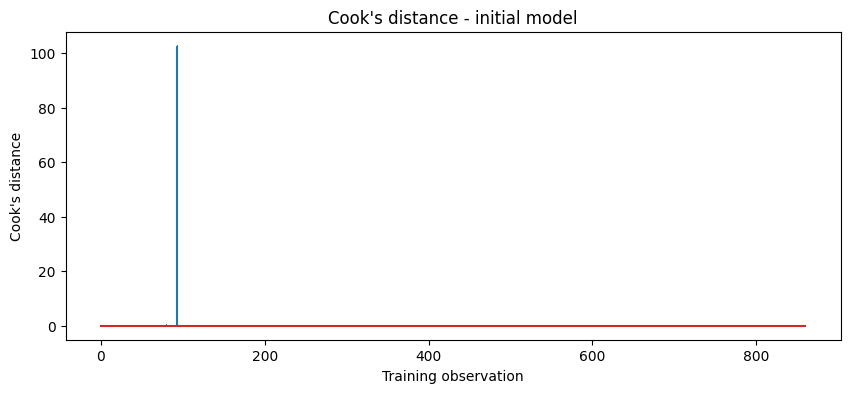

Largest Cook's distances in the training set:
        Id                                              Model  Price  \
80      81                TOYOTA Corolla 1.6 5drs 1 4/5-Doors  18950   
110    112           TOYOTA Corolla VERSO 2.0 D4D SOL (7) MPV  31000   
1058  1063  TOYOTA Corolla 2.0 ST WGN LINEA TERRA DSL Stat...  10500   
523    526        TOYOTA Corolla 1.6 HB LINEA TERRA 2/3-Doors  18950   
601    605           TOYOTA Corolla 2.0 d HB Diesel 2/3-Doors   7500   
8        9        TOYOTA Corolla 1800 T SPORT VVT I 2/3-Doors  21500   

      Age_08_04      KM     CC   HP  Cooks_D  
80           25   20019  16000  110  102.701  
110           4    4000   2000  116    0.082  
1058         77  172980   2000   72    0.074  
523          49   49568   1600  110    0.057  
601          50       1   2000   90    0.056  
8            27   19700   1800  192    0.056  

Largest absolute residuals in the test set:
      Id                                              Model  Price  Age_08_

In [8]:
### Step 5 again: influential and extreme records ----

# Cook's distance on the training set.
influence = model_base.get_influence()
cooks_d = pd.Series(influence.cooks_distance[0], index=X_train.index)

plt.figure(figsize=(10, 4))
plt.stem(range(len(cooks_d)), cooks_d.values, markerfmt=',')
plt.xlabel('Training observation')
plt.ylabel("Cook's distance")
plt.title("Cook's distance - initial model")
plt.show()

print("Largest Cook's distances in the training set:")
top_cook = cooks_d.sort_values(ascending=False).head(6)
print(cars_raw.loc[top_cook.index,
                   ['Id', 'Model', 'Price', 'Age_08_04', 'KM', 'CC', 'HP']]
      .assign(Cooks_D=top_cook.round(3)))

# Largest test residuals help check whether one partition contains unusual cars.
test_resid = y_test - pred_test_base
print(); print('Largest absolute residuals in the test set:')
top_test = test_resid.abs().sort_values(ascending=False).head(6)
print(cars_raw.loc[top_test.index,
                   ['Id', 'Model', 'Price', 'Age_08_04', 'KM', 'CC']]
      .assign(Abs_Residual=top_test.round(0)))

print(); print('Clearly implausible measurements:')
suspect = cars_raw.loc[
    (cars_raw['CC'] > 5000) |
    ((cars_raw['KM'] < 100) & (cars_raw['Age_08_04'] > 24)),
    ['Id', 'Model', 'Price', 'Age_08_04', 'KM', 'CC']
]
print(suspect.to_string(index=False))

print(); print('High-priced Corolla Verso records (kept, not deleted):')
print(cars_raw.loc[cars_raw['Model'].str.contains('VERSO', case=False, na=False),
                   ['Id', 'Price', 'Age_08_04', 'KM', 'CC', 'Weight']].to_string(index=False))

In [9]:
# Remove only records with clear measurement problems.
# Keep the original train/test membership so the before/after comparison is fair.
bad_ids = [81, 605, 1442]

train_clean = train_data.loc[~train_data['Id'].isin(bad_ids)].copy()
test_clean = test_data.loc[~test_data['Id'].isin(bad_ids)].copy()

Xc_train = train_clean[predictors].astype(float)
yc_train = train_clean['Price']
Xc_test = test_clean[predictors].astype(float)
yc_test = test_clean['Price']

print(f'Removed {len(train_data)-len(train_clean)} record(s) from training and '
      f'{len(test_data)-len(test_clean)} from test.')
print(f'Clean training n = {len(train_clean)}, clean test n = {len(test_clean)}')
print(); print('Removed records:')
print(cars_raw.loc[cars_raw['Id'].isin(bad_ids),
                   ['Id', 'Model', 'Price', 'Age_08_04', 'KM', 'CC']].to_string(index=False))

Removed 2 record(s) from training and 1 from test.
Clean training n = 859, clean test n = 574

Removed records:
  Id                                       Model  Price  Age_08_04    KM    CC
  81         TOYOTA Corolla 1.6 5drs 1 4/5-Doors  18950         25 20019 16000
 605    TOYOTA Corolla 2.0 d HB Diesel 2/3-Doors   7500         50     1  2000
1442 TOYOTA Corolla 1.6 LB LINEA TERRA 4/5-Doors   6950         76     1  1600


### Q6. Compare training and test results, identify extreme records, and justify removals

The original train/test results are already close, so there is not a large partition problem. Still, Cook's distance finds one extreme training record: **Id 81 has `CC = 16000`**, which is not a realistic Corolla engine size. Two other records, **Ids 605 and 1442**, show **1 km on the odometer at 50 and 76 months old**. I treat those three as measurement/data-entry problems and remove them.

I **did not remove the expensive Corolla Verso cars** just because their residuals are large. There are several similar Verso records with internally consistent specifications, so deleting only the expensive ones would be cherry-picking. This follows the rule used in class: remove an observation for a defensible data reason, not simply because the model misses it.

I also kept the original train/test membership after removal. That way, the next before/after comparison is measuring the effect of cleaning rather than a different random split.

Initial model:
                Training set  Test set
R-squared              0.893     0.882
Adj. R-squared         0.891     0.879
RMSE                1201.343  1219.465
MAE                  911.845   889.973

Same model after removing the three bad records:
                Training set  Test set
R-squared              0.898     0.890
Adj. R-squared         0.895     0.887
RMSE                1172.881  1177.835
MAE                  882.296   863.845

Selected coefficient changes:
                  Initial  Cleaned   Change
Age_08_04         -111.62  -109.23     2.39
KM                  -0.02    -0.02    -0.00
CC                  -0.10    -3.81    -3.71
HP                  30.43    62.30    31.87
Quarterly_Tax       16.98    14.20    -2.78
Automatic_airco   3043.12  2878.89  -164.23
Fuel_Type_Diesel  1844.19  4368.55  2524.36
Fuel_Type_Petrol  2000.91  1594.50  -406.41


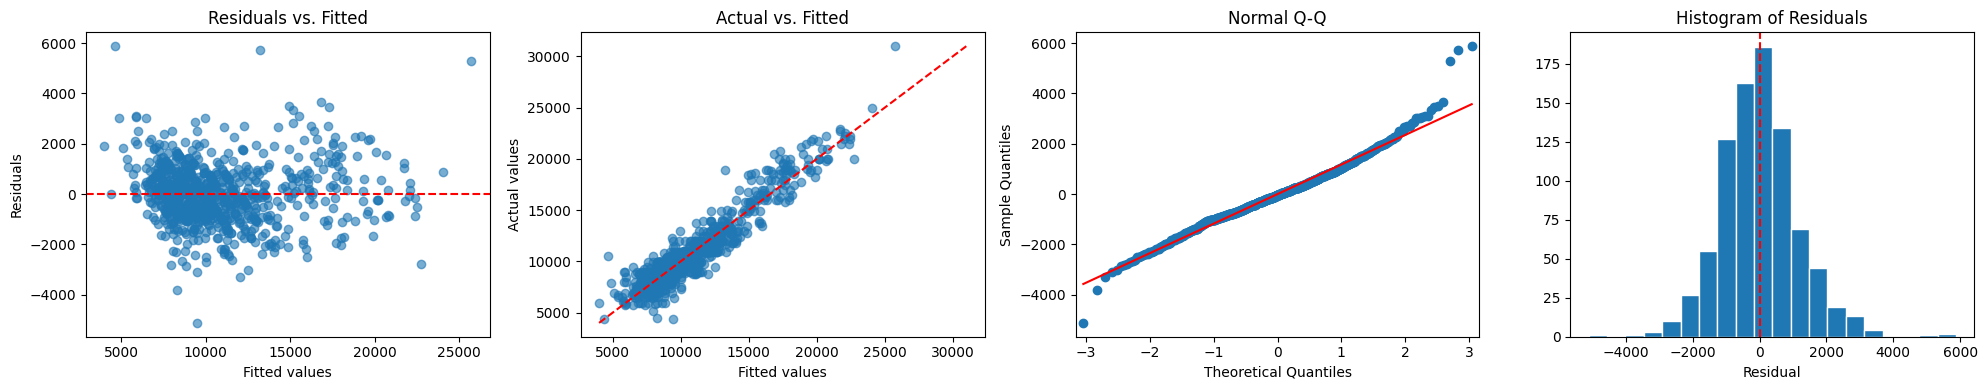

In [10]:
# Refit the same 16-predictor specification after cleaning.
model_clean = sm.OLS(
    yc_train,
    sm.add_constant(Xc_train, has_constant='add')
).fit()

print('Initial model:')
print(scorecard(model_base, X_train, y_train, X_test, y_test))
print(); print('Same model after removing the three bad records:')
print(scorecard(model_clean, Xc_train, yc_train, Xc_test, yc_test))

compare_coef = pd.DataFrame({
    'Initial': model_base.params,
    'Cleaned': model_clean.params
})
compare_coef['Change'] = compare_coef['Cleaned'] - compare_coef['Initial']

print(); print('Selected coefficient changes:')
print(compare_coef.loc[
    ['Age_08_04', 'KM', 'CC', 'HP', 'Quarterly_Tax',
     'Automatic_airco', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol']
].round(2))

diagnostic_plots(model_clean, yc_train)

### Q7. Re-run the model and compare training/test performance. What did you discover?

Cleaning helps without creating a train/test gap. Test RMSE falls from about **EUR 1,219 to EUR 1,178**, test MAE falls from **EUR 890 to EUR 864**, and test R-squared rises from **0.882 to 0.890**. Training performance improves by a similar amount.

The biggest change is in the engine coefficients. Once the impossible 16,000 cc record is removed, the `CC` and `HP` estimates move a lot, which shows that one bad engine-size value was distorting that part of the model.

The residual plots are cleaner, but there is still some widening at higher prices and a slight curve. That means the next improvement should come from a better model shape, not from deleting more legitimate cars.

In [11]:
### Q8: alternative model specifications ----

# The revised instructions replace stepwise regression with trying a few
# specifications of my own. I do that below. I also ran the three automatic
# selection routines as a cross-check on which linear subset they land on,
# but the models I compare and choose between are my own three.

# Use all usable car specifications. Id and Model are identifiers/descriptions,
# Mfg_Month and Mfg_Year duplicate Age_08_04, and Cylinders is constant.
selection_data = cars_raw.loc[~cars_raw['Id'].isin(bad_ids)].copy()
selection_data = pd.get_dummies(
    selection_data,
    columns=['Fuel_Type', 'Color'],
    drop_first=True,
    dtype=int
)

selection_pool = [
    c for c in selection_data.columns
    if c not in ['Id', 'Model', 'Price', 'Mfg_Month', 'Mfg_Year', 'Cylinders']
    and pd.api.types.is_numeric_dtype(selection_data[c])
]

sel_train = selection_data.loc[train_clean.index]
sel_test = selection_data.loc[test_clean.index]

print(f'Candidate predictors considered in selection: {len(selection_pool)}')


def fit_selection(cols):
    if cols:
        X = sm.add_constant(sel_train[cols].astype(float), has_constant='add')
    else:
        X = pd.DataFrame({'const': 1.0}, index=sel_train.index)
    return sm.OLS(yc_train, X).fit()


def forward_aic(candidates):
    selected = []
    current_aic = fit_selection(selected).aic

    while True:
        remaining = [c for c in candidates if c not in selected]
        if not remaining:
            break
        trials = [(fit_selection(selected + [c]).aic, c) for c in remaining]
        best_aic, best_var = min(trials)
        if best_aic < current_aic:
            selected.append(best_var)
            current_aic = best_aic
        else:
            break
    return selected, fit_selection(selected)


def backward_aic(candidates):
    selected = candidates.copy()
    current_aic = fit_selection(selected).aic

    while len(selected) > 1:
        trials = []
        for c in selected:
            cols = [x for x in selected if x != c]
            trials.append((fit_selection(cols).aic, c))
        best_aic, remove_var = min(trials)
        if best_aic < current_aic:
            selected.remove(remove_var)
            current_aic = best_aic
        else:
            break
    return selected, fit_selection(selected)


def stepwise_aic(candidates):
    selected = []
    current_aic = fit_selection(selected).aic

    while True:
        changed = False
        remaining = [c for c in candidates if c not in selected]

        if remaining:
            trials = [(fit_selection(selected + [c]).aic, c) for c in remaining]
            best_aic, best_var = min(trials)
            if best_aic < current_aic:
                selected.append(best_var)
                current_aic = best_aic
                changed = True

        while selected:
            trials = []
            for c in selected:
                cols = [x for x in selected if x != c]
                trials.append((fit_selection(cols).aic, c))
            best_aic, remove_var = min(trials)
            if best_aic < current_aic:
                selected.remove(remove_var)
                current_aic = best_aic
                changed = True
            else:
                break

        if not changed:
            break

    return selected, fit_selection(selected)

Candidate predictors considered in selection: 42


In [12]:
forward_cols, forward_model = forward_aic(selection_pool)
backward_cols, backward_model = backward_aic(selection_pool)
stepwise_cols, stepwise_model = stepwise_aic(selection_pool)

selection_specs = {
    'Forward selection': (forward_cols, forward_model),
    'Backward selection': (backward_cols, backward_model),
    'Stepwise selection': (stepwise_cols, stepwise_model)
}

for name, (cols, model) in selection_specs.items():
    pred = model.predict(sm.add_constant(sel_test[cols].astype(float), has_constant='add'))
    print(); print(f'{name}: {len(cols)} predictors')
    print(cols)
    print(f'Test RMSE = {np.sqrt(mean_squared_error(yc_test, pred)):,.1f} EUR, '
          f'Test R2 = {r2_score(yc_test, pred):.3f}')


Forward selection: 23 predictors
['Age_08_04', 'Automatic_airco', 'KM', 'Weight', 'HP', 'Powered_Windows', 'BOVAG_Guarantee', 'CC', 'Quarterly_Tax', 'Guarantee_Period', 'Color_White', 'Airco', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'ABS', 'Mfr_Guarantee', 'Boardcomputer', 'Sport_Model', 'CD_Player', 'Tow_Bar', 'Backseat_Divider', 'Power_Steering', 'Color_Black']
Test RMSE = 1,150.4 EUR, Test R2 = 0.895

Backward selection: 23 predictors
['Age_08_04', 'KM', 'HP', 'CC', 'Quarterly_Tax', 'Weight', 'Mfr_Guarantee', 'BOVAG_Guarantee', 'Guarantee_Period', 'ABS', 'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player', 'Powered_Windows', 'Power_Steering', 'Sport_Model', 'Backseat_Divider', 'Tow_Bar', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Color_Black', 'Color_White']
Test RMSE = 1,150.4 EUR, Test R2 = 0.895

Stepwise selection: 23 predictors
['Age_08_04', 'Automatic_airco', 'KM', 'Weight', 'HP', 'Powered_Windows', 'BOVAG_Guarantee', 'CC', 'Quarterly_Tax', 'Guarantee_Period', 'Color_White

In [13]:
# Three additional models, built one change at a time.
def add_terms(df):
    out = df.copy()
    out['Age_sq'] = out['Age_08_04'] ** 2
    out['Age_x_KM'] = out['Age_08_04'] * out['KM'] / 1000
    return out

train_fe = add_terms(train_clean)
test_fe = add_terms(test_clean)

custom_specs = {
    'Model A: + Weight + BOVAG': predictors + ['Weight', 'BOVAG_Guarantee'],
    'Model B: + Age squared': predictors + ['Weight', 'BOVAG_Guarantee', 'Age_sq'],
    'Model C: + Age squared + Age x KM': predictors + [
        'Weight', 'BOVAG_Guarantee', 'Age_sq', 'Age_x_KM'
    ]
}

custom_models = {}
for name, cols in custom_specs.items():
    custom_models[name] = sm.OLS(
        yc_train,
        sm.add_constant(train_fe[cols].astype(float), has_constant='add')
    ).fit()

# Compare every serious candidate in one table.
def model_row(model, Xtr, ytr, Xte, yte):
    pred_tr = model.predict(sm.add_constant(Xtr, has_constant='add'))
    pred_te = model.predict(sm.add_constant(Xte, has_constant='add'))
    return {
        'Train adj. R2': model.rsquared_adj,
        'Train RMSE': np.sqrt(mean_squared_error(ytr, pred_tr)),
        'Test R2': r2_score(yte, pred_te),
        'Test RMSE': np.sqrt(mean_squared_error(yte, pred_te)),
        'Test MAE': mean_absolute_error(yte, pred_te)
    }

rows = {
    'Initial baseline': model_row(model_base, X_train, y_train, X_test, y_test),
    'Cleaned baseline': model_row(model_clean, Xc_train, yc_train, Xc_test, yc_test)
}

for name, (cols, model) in selection_specs.items():
    rows[name] = model_row(
        model,
        sel_train[cols].astype(float), yc_train,
        sel_test[cols].astype(float), yc_test
    )

for name, cols in custom_specs.items():
    rows[name] = model_row(
        custom_models[name],
        train_fe[cols].astype(float), yc_train,
        test_fe[cols].astype(float), yc_test
    )

model_comparison = pd.DataFrame(rows).T.sort_values('Test RMSE')
print(model_comparison.round(3))

                                   Train adj. R2  Train RMSE  Test R2  \
Model B: + Age squared                     0.913    1066.639    0.909   
Model C: + Age squared + Age x KM          0.915    1054.284    0.908   
Model A: + Weight + BOVAG                  0.907    1104.228    0.895   
Forward selection                          0.910    1084.113    0.895   
Stepwise selection                         0.910    1084.113    0.895   
Backward selection                         0.910    1084.113    0.895   
Cleaned baseline                           0.895    1172.881    0.890   
Initial baseline                           0.891    1201.343    0.882   

                                   Test RMSE  Test MAE  
Model B: + Age squared              1075.120   786.271  
Model C: + Age squared + Age x KM   1076.087   789.874  
Model A: + Weight + BOVAG           1149.801   823.433  
Forward selection                   1150.430   826.016  
Stepwise selection                  1150.430   826.016  


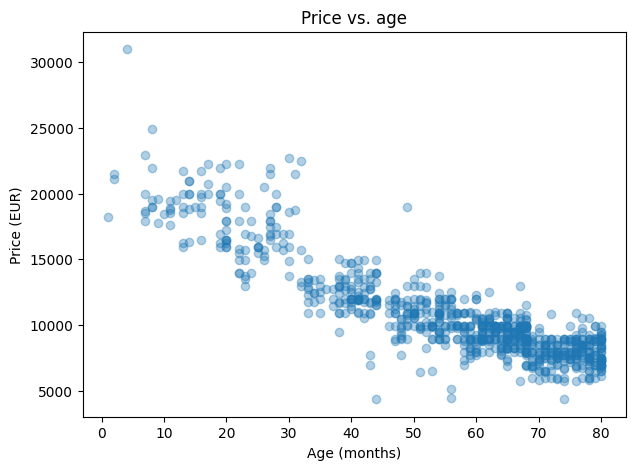

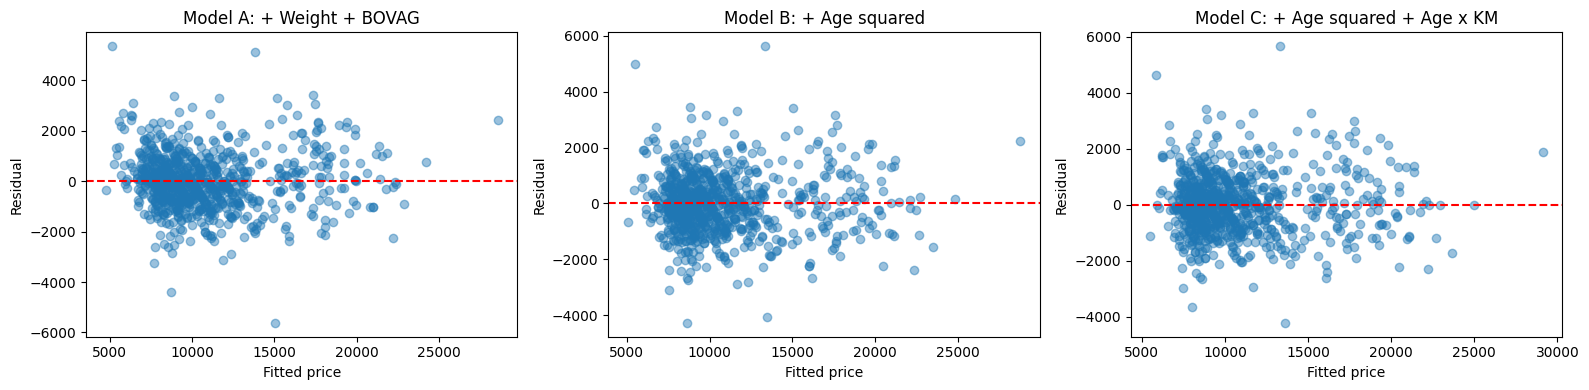

In [14]:
# The curvature in age is visible before and after fitting.
plt.figure(figsize=(7, 5))
plt.scatter(train_clean['Age_08_04'], yc_train, alpha=0.35)
plt.xlabel('Age (months)')
plt.ylabel('Price (EUR)')
plt.title('Price vs. age')
plt.show()

# Residual-vs-fitted plots for the three added specifications.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, custom_models.items()):
    ax.scatter(model.fittedvalues, model.resid, alpha=0.45)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Fitted price')
    ax.set_ylabel('Residual')
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Q8. Alternative model specifications compared to the baseline

Following the revised instructions on Canvas, I built three specifications of my own instead of relying
on stepwise regression, changing one thing at a time so I could see what each change bought.

- **Model A:** adds `Weight` and `BOVAG_Guarantee`, two specifications the requested list left out. Test
  RMSE improves from EUR 1,178 to about **EUR 1,150**. Both are strongly significant.
- **Model B:** also adds **Age squared**. Test RMSE falls clearly to about **EUR 1,075** and test
  R-squared rises to about **0.909**. The squared term is highly significant.
- **Model C:** also adds an **Age x KM** interaction. It fits the training data a little better, but test
  RMSE is about **EUR 1,076**, slightly worse than Model B. It doesn't earn its complexity.

The raw age plot and the residual plots explain why Model B helps. Depreciation is steeper for newer cars
and flattens as cars get older, so one straight age slope is too restrictive. The residual-vs-fitted plot
for Model A still bends; for Models B and C it's much flatter.

As a cross-check I also ran forward, backward and stepwise selection on AIC over 42 candidate predictors,
leaving out the ID and free-text model name, the manufacturing month and year (they duplicate age), and
`Cylinders` (constant). All three land on the same 23-variable linear specification, which says the
selected linear subset is stable. Its test RMSE is about EUR 1,150, better than the cleaned baseline but
no better than my own Model A and clearly worse than Model B. Adding the squared age term beat anything a
purely linear search could find, which is the main lesson here.

Worth flagging what the search kept: `Color_White` and `Color_Black` both survive all three routines. I
don't believe paint color drives resale value, and neither does the business logic. With 42 candidates
and 859 training cars, a search run on AIC alone will pick up predictors that happen to help in this
sample, and that's the known weakness of automatic selection. It's part of why I judged my own three
models on test-set error instead of letting a search pick the specification for me.

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     452.4
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        22:56:08   Log-Likelihood:                -7208.0
No. Observations:                 859   AIC:                         1.446e+04
Df Residuals:                     838   BIC:                         1.456e+04
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             2729.1734   1773.639  

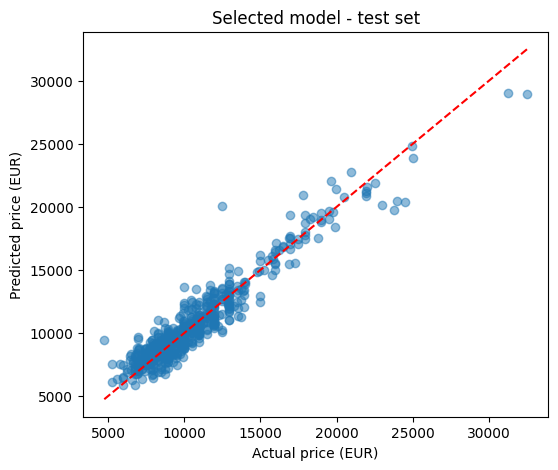

In [15]:
### Q9: selected model ----

final_cols = custom_specs['Model B: + Age squared']
model_final = custom_models['Model B: + Age squared']

print(model_final.summary())
print(); print('Final model scorecard:')
print(scorecard(
    model_final,
    train_fe[final_cols].astype(float), yc_train,
    test_fe[final_cols].astype(float), yc_test
))

pred_final = model_final.predict(
    sm.add_constant(test_fe[final_cols].astype(float), has_constant='add')
)
final_abs_error = (yc_test - pred_final).abs()

print(); print('Test error bands:')
for band in [500, 1000, 1500, 2000]:
    print(f'Within {band:4d} EUR: {(final_abs_error < band).mean():.1%}')

plt.figure(figsize=(6, 5))
plt.scatter(yc_test, pred_final, alpha=0.5)
lims = [min(yc_test.min(), pred_final.min()), max(yc_test.max(), pred_final.max())]
plt.plot(lims, lims, color='red', linestyle='--')
plt.xlabel('Actual price (EUR)')
plt.ylabel('Predicted price (EUR)')
plt.title('Selected model - test set')
plt.show()

### Q9. Select a model to report to the client and justify it

I would use **Model B: the cleaned data, the original requested predictors, plus Weight, BOVAG_Guarantee and Age squared**.

It has the best test RMSE of the models tried: about **EUR 1,075**, compared with EUR 1,219 for the original model and EUR 1,178 for the cleaned baseline. Test R-squared is about **0.909** and MAE is about **EUR 786**. Training and test performance are also close, so there is no sign that the improvement only exists in the training sample.

I prefer Model B over the slightly more complicated Model C because Model C improves training fit but makes test RMSE a little worse. Model B is therefore the better balance of accuracy, interpretability and simplicity.

In [16]:
### Step 6: Marginal effects and business interpretation ----

b = model_final.params

# With Age squared in the model, the effect of one more month depends on age.
age_effect = b['Age_08_04'] + 2 * b['Age_sq'] * train_fe['Age_08_04']
km_effect_10k = b['KM'] * 10000

print('Marginal effect of age (EUR per additional month):')
print(age_effect.describe().round(1))
print(); print(f'Mileage effect: {km_effect_10k:,.0f} EUR per additional 10,000 km')

options = [
    'Automatic_airco', 'BOVAG_Guarantee', 'Airco', 'Powered_Windows',
    'Automatic', 'Mfr_Guarantee', 'CD_Player', 'Sport_Model', 'Tow_Bar'
]
option_table = pd.DataFrame({
    'Estimated price effect (EUR)': model_final.params[options].round(0),
    'p_value': model_final.pvalues[options].round(3)
}).sort_values('Estimated price effect (EUR)', ascending=False)

print(); print('Selected option effects:')
print(option_table)

print(); print('Other influential specification coefficients:')
print(pd.DataFrame({
    'Coefficient': model_final.params[
        ['HP', 'CC', 'Quarterly_Tax', 'Weight',
         'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Guarantee_Period']
    ].round(1),
    'p_value': model_final.pvalues[
        ['HP', 'CC', 'Quarterly_Tax', 'Weight',
         'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Guarantee_Period']
    ].round(3)
}))

# A simple age/mileage guide for an otherwise typical Corolla.
typical = train_fe[final_cols].astype(float).median()
rows = []
for months in [12, 24, 36, 48, 60, 72]:
    row = {'Age (months)': months}
    for km in [30000, 60000, 90000, 120000]:
        car = typical.copy()
        car['Age_08_04'] = months
        car['KM'] = km
        car['Age_sq'] = months ** 2
        price = model_final.predict(
            sm.add_constant(car.to_frame().T, has_constant='add')
        ).iloc[0]
        row[km] = int(round(float(price), -1))
    rows.append(row)

price_guide = pd.DataFrame(rows).set_index('Age (months)')
print(); print('Estimated resale price for an otherwise typical Corolla:')
print(price_guide)

Marginal effect of age (EUR per additional month):
count    859.0
mean     -95.1
std       32.4
min     -188.5
25%     -115.3
50%      -86.4
75%      -71.1
max      -54.1
Name: Age_08_04, dtype: float64

Mileage effect: -159 EUR per additional 10,000 km

Selected option effects:
                 Estimated price effect (EUR)  p_value
Automatic_airco                        2172.0    0.000
BOVAG_Guarantee                         523.0    0.000
Airco                                   388.0    0.000
Powered_Windows                         266.0    0.004
Automatic                               239.0    0.147
Mfr_Guarantee                           236.0    0.004
CD_Player                               112.0    0.291
Sport_Model                              -8.0    0.929
Tow_Bar                                -108.0    0.217

Other influential specification coefficients:
                  Coefficient  p_value
HP                       45.8      0.0
CC                       -3.6      0.0
Quarte

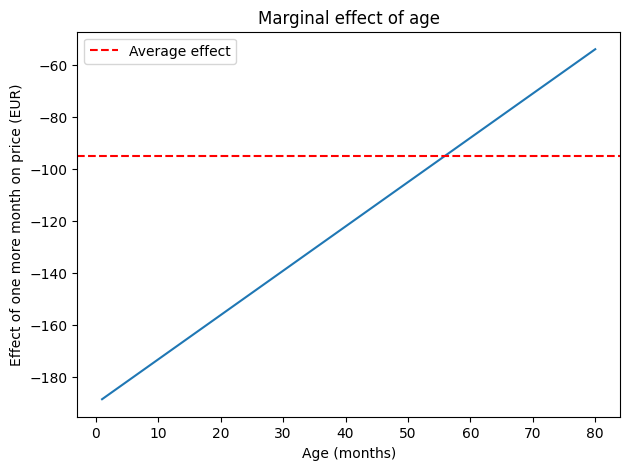

At 12 months: -170 EUR per extra month
At 72 months: -68 EUR per extra month


In [17]:
# Plot the changing effect of age, as in the marginal-effects examples from class.
age_grid = np.linspace(train_fe['Age_08_04'].min(), train_fe['Age_08_04'].max(), 100)
age_mfx_grid = b['Age_08_04'] + 2 * b['Age_sq'] * age_grid

plt.figure(figsize=(7, 5))
plt.plot(age_grid, age_mfx_grid)
plt.axhline(age_effect.mean(), color='red', linestyle='--', label='Average effect')
plt.xlabel('Age (months)')
plt.ylabel('Effect of one more month on price (EUR)')
plt.title('Marginal effect of age')
plt.legend()
plt.show()

print(f'At 12 months: {b["Age_08_04"] + 2*b["Age_sq"]*12:,.0f} EUR per extra month')
print(f'At 72 months: {b["Age_08_04"] + 2*b["Age_sq"]*72:,.0f} EUR per extra month')

### Q10. Marginal effects and plain-English guidance for the dealership

**Age is the strongest driver.** Because the selected model includes age squared, the depreciation rate changes as the car gets older. On average, another month lowers expected resale value by about **EUR 95**, but the effect is about **EUR 170 per month at one year old** and about **EUR 68 per month at six years old**. In other words, newer cars lose value faster in euro terms.

**Mileage is next.** Holding the other specifications fixed, another 10,000 km lowers expected resale price by about **EUR 159**.

**Automatic climate control is the standout option**, worth roughly **EUR 2,170** in the model. A BOVAG guarantee is worth about **EUR 520**, ordinary air conditioning about **EUR 390**, powered windows about **EUR 270**, and a manufacturer guarantee about **EUR 240**. CD player, sport model and tow bar do not show a reliable premium after the other specifications are taken into account.

For a salesperson, the practical order is: start with **age**, adjust for the exact **mileage**, then look at the **engine/fuel/weight/road-tax package**, and finally add value for the few options and guarantees that actually move resale price. Those engine variables overlap, so the individual `CC` coefficient should not be used as a literal per-cc price rule. The age/mileage table above gives a quick base estimate for an otherwise typical Corolla.

The final model's test MAE is about **EUR 786**. About **71%** of test cars are within EUR 1,000 of the actual price and about **87%** are within EUR 1,500. That is good enough to anchor an offer, but not to replace a physical inspection. Condition, accident history, tyres and service records are not in this dataset, so the dealership should still leave a margin buffer around the model estimate.